# Executive EDA Report — WHO Health Data for Mexico
**Time Series — Units 1 & 2 project**

**Made by Cristian Misael Torres Martínez**

Variables analysed in this notebook:
1. Population growth rate (annual, %)
2. Life expectancy at birth (annual, both sexes, years)
3. Top 10 causes of death (annual, deaths per 100,000 population)

All three series are **annual** (one observation per year), so every lag `k` in this notebook means *k years*.

In [54]:
# Setup (same configuration style as the course notebooks)
import warnings
warnings.filterwarnings("ignore")
import numpy as np
np.set_printoptions(suppress=True)
np.random.seed(1)
import pandas as pd
pd.set_option("max_colwidth", 100)
pd.set_option("display.precision", 3)
import seaborn as sns
sns.set_style("whitegrid")
import matplotlib.pyplot as plt
plt.style.use("ggplot")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "figure.constrained_layout.use": True,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "grid.alpha": 1.0,
})
from statsmodels.graphics.tsaplots import plot_acf

## 1. Load the data

In [55]:
# Population (UN World Population Prospects estimates, the source used by WHO), 1950-2023
pop_raw = pd.read_excel("Population mexico.xlsx")
pop = (pop_raw[["Year", "Population Growth Rate (percentage)"]]
       .rename(columns={"Year": "year", "Population Growth Rate (percentage)": "y"}))
pop["ds"] = pd.to_datetime(pop["year"].astype(str))
pop

,year,y,ds
0,1950,2.584,1950-01-01
1,1951,2.657,1951-01-01
2,1952,2.706,1952-01-01
3,1953,2.780,1953-01-01
4,1954,2.850,1954-01-01
...,...,...,...
69,2019,0.945,2019-01-01
70,2020,0.697,2020-01-01
71,2021,0.638,2021-01-01
72,2022,0.868,2022-01-01


In [56]:
# Life expectancy at birth (WHO, indicator WHOSIS_000001). Only the TOTAL (both sexes) series is used.
le_raw = pd.read_excel("Life expectancy at birth.xlsx")
print(le_raw["DIM_SEX"].unique())
le = (le_raw.loc[le_raw["DIM_SEX"] == "TOTAL", ["DIM_TIME", "AMOUNT_N"]]
      .rename(columns={"DIM_TIME": "year", "AMOUNT_N": "y"})
      .sort_values("year")
      .reset_index(drop=True))
le["ds"] = pd.to_datetime(le["year"].astype(str))
le

['FEMALE' 'MALE' 'TOTAL']


,year,y,ds
0,2000,74.218,2000-01-01
1,2001,74.551,2001-01-01
2,2002,74.589,2002-01-01
3,2003,74.628,2003-01-01
4,2004,75.043,2004-01-01
5,2005,74.927,2005-01-01
6,2006,75.336,2006-01-01
7,2007,75.525,2007-01-01
8,2008,75.087,2008-01-01
9,2009,75.142,2009-01-01


In [57]:
# Top 10 causes of death per year (built from WHO Global Health Estimates)
deaths = pd.read_csv("causas_muerte_mexico_2000_2023_OMS.csv")
deaths = deaths.rename(columns={"anio": "year", "ranking_anual": "rank",
                                "causa_muerte": "cause",
                                "muertes_por_100000_habitantes": "y"})
deaths["ds"] = pd.to_datetime(deaths["year"].astype(str))
deaths.head(12)

,year,rank,tipo_persona,grupo_edad,pais,codigo_causa_oms,cause,y,ds
0,2000,1,Población general,Todas las edades,México,1130,Ischaemic heart disease,59.27,2000-01-01
1,2000,2,Población general,Todas las edades,México,1230,Cirrhosis of the liver,39.79,2000-01-01
2,2000,3,Población general,Todas las edades,México,800,Diabetes mellitus,35.29,2000-01-01
3,2000,4,Población general,Todas las edades,México,1140,Stroke,26.50,2000-01-01
4,2000,5,Población general,Todas las edades,México,1530,Road injury,23.49,2000-01-01
5,2000,6,Población general,Todas las edades,México,390,Lower respiratory infections,22.63,2000-01-01
6,2000,7,Población general,Todas las edades,México,1180,Chronic obstructive pulmonary disease,21.90,2000-01-01
7,2000,8,Población general,Todas las edades,México,1620,Interpersonal violence,20.97,2000-01-01
8,2000,9,Población general,Todas las edades,México,1270,Kidney diseases,19.80,2000-01-01
9,2000,10,Población general,Todas las edades,México,1400,Congenital anomalies,16.48,2000-01-01


## 2. Data overview and coverage

In [58]:
coverage = pd.DataFrame({
    "series": ["Population growth rate", "Life expectancy at birth", "Causes of death"],
    "first_year": [pop["year"].min(), le["year"].min(), deaths["year"].min()],
    "last_year": [pop["year"].max(), le["year"].max(), deaths["year"].max()],
    "n_years": [pop["year"].nunique(), le["year"].nunique(), deaths["year"].nunique()],
})
coverage

,series,first_year,last_year,n_years
0,Population growth rate,1950,2023,74
1,Life expectancy at birth,2000,2021,22
2,Causes of death,2000,2023,24


In [59]:
# How many different causes appear in the yearly top 10?
deaths["cause"].nunique()

14

## 3. Summary statistics
Same summary used in class (min, quartiles, max), computed with native pandas.

In [60]:
def summary(s):
    return pd.Series({"n": s.count(), "mean": s.mean(), "std": s.std(),
                      "min": s.min(), "p25": s.quantile(.25), "median": s.median(),
                      "p75": s.quantile(.75), "max": s.max()})

pd.DataFrame({"Population growth rate (%)": summary(pop["y"]),
              "Life expectancy (years)": summary(le["y"])}).T

,n,mean,std,min,p25,median,p75,max
Population growth rate (%),74.0,2.116,0.808,0.638,1.431,2.005,2.902,3.315
Life expectancy (years),22.0,74.909,1.401,70.833,74.703,75.239,75.816,75.940


In [61]:
summary_causes = deaths.groupby("cause")["y"].apply(summary).unstack()
summary_causes.sort_values("mean", ascending=False)

,n,mean,std,min,p25,median,p75,max
cause,,,,,,,,
COVID-19,3.0,253.357,158.800,69.99,207.390,344.790,345.040,345.29
Ischaemic heart disease,24.0,85.662,22.096,59.27,66.153,79.405,102.885,130.68
Diabetes mellitus,24.0,56.212,11.671,35.29,48.057,54.675,68.233,72.96
Cirrhosis of the liver,24.0,37.087,2.228,32.95,34.790,37.395,39.010,40.17
Interpersonal violence,24.0,35.852,15.806,14.78,19.240,34.115,51.292,58.48
Stroke,24.0,28.103,1.291,26.09,26.608,28.200,29.210,30.14
Kidney diseases,24.0,27.830,3.968,19.80,25.143,29.500,30.633,32.87
Chronic obstructive pulmonary disease,24.0,23.220,1.843,18.48,22.812,23.680,24.310,25.58
Road injury,24.0,22.748,2.040,19.09,21.742,22.925,24.032,26.01


## 4. Helper functions
* **Time plot + trend**: the trend is estimated with a centred moving average.
  With annual data there is **no seasonal component** (seasonality is a pattern *within* the year),
  so the series is split only into trend and remainder: `remainder = y - trend`.
* **Lag plots**: same 3×3 layout as the beer example, coloured by year instead of quarter.
* **ACF**: autocorrelation for each lag.

In [62]:
def plot_time_trend(df, title, ylabel, window=5, mark_years=None, break_year=None):
    # break_year: if given, the trend is computed separately before and after that year,
    # so a sudden shock is not smeared over the neighbouring years by the moving average
    df = df.sort_values("ds").copy()
    if break_year is None:
        df["trend"] = df["y"].rolling(window, center=True).mean()
    else:
        seg = (df["year"] >= break_year).astype(int)
        df["trend"] = df.groupby(seg)["y"].transform(lambda s: s.rolling(window, center=True).mean())
    df["remainder"] = df["y"] - df["trend"]
    fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
    axes[0].plot(df["ds"], df["y"], marker="o", ms=3, color="#000000", label="observed")
    axes[0].plot(df["ds"], df["trend"], color="#D55E00", lw=2, label=f"trend (MA-{window})")
    axes[0].set(title=title, ylabel=ylabel)
    axes[0].legend()
    axes[1].plot(df["ds"], df["y"].diff(), marker="o", ms=3, color="#0072B2")
    axes[1].axhline(0, color=".5", ls="--", lw=1)
    axes[1].set(title="Year-over-year change (first difference)", ylabel="change")
    axes[2].bar(df["ds"], df["remainder"], width=200, color="#009E73")
    axes[2].axhline(0, color=".5", lw=1)
    axes[2].set(title="Remainder (observed - trend)", ylabel="remainder", xlabel="Year")
    if mark_years:
        for yr in mark_years:
            for ax in axes:
                ax.axvline(pd.Timestamp(str(yr)), color="red", ls=":", lw=1)
    fig.show()
    return df


def plot_lags(df, name, max_lag=9):
    df = df.sort_values("ds").copy()
    pad = 0.05 * (df["y"].max() - df["y"].min())
    lims = df["y"].min() - pad, df["y"].max() + pad
    fig, axes = plt.subplots(3, 3, figsize=(9, 8), sharex=True, sharey=True)
    for i, ax in enumerate(axes.flat):
        lag = i + 1
        d = df.assign(lag=df["y"].shift(lag))
        sc = ax.scatter(d["lag"], d["y"], c=d["year"], cmap="viridis",
                        vmin=df["year"].min(), vmax=df["year"].max(), s=25)
        ax.plot(lims, lims, color=".5", ls="--", lw=1, zorder=-1)
        ax.set(title=f"lag {lag}", xlim=lims, ylim=lims, aspect="equal")
    fig.colorbar(sc, ax=axes, label="Year", shrink=0.8, format="%d")
    fig.supxlabel(f"lag({name}, k)  [k in years]")
    fig.supylabel(name)
    fig.show()


def plot_autocorr(df, name):
    n_lags = min(20, len(df) // 2 - 1)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    plot_acf(df.sort_values("ds")["y"], lags=n_lags, ax=ax)
    ax.set(title=f"ACF — {name}", xlabel="lag (years)")
    fig.show()

## 5. Population growth rate (1950–2023)

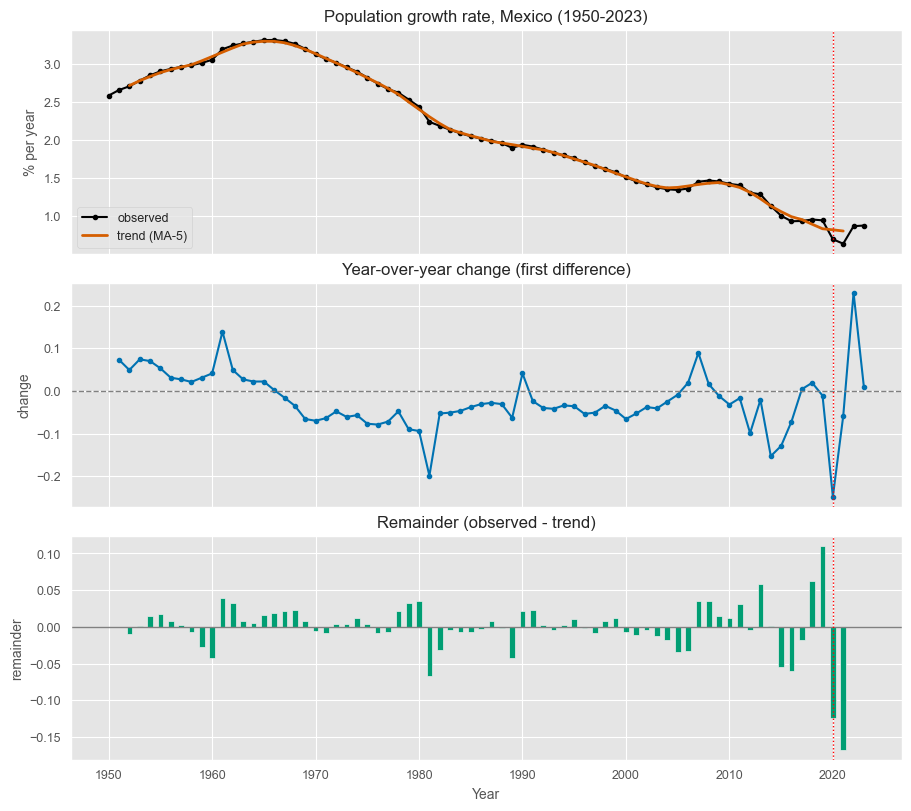

In [63]:
pop_dec = plot_time_trend(pop, "Population growth rate, Mexico (1950-2023)",
                          "% per year", mark_years=[2020])

In [64]:
# Largest remainders (possible outliers / structural breaks)
pop_dec.reindex(pop_dec["remainder"].abs().sort_values(ascending=False).index)[["year", "y", "trend", "remainder"]].head(5)

,year,y,trend,remainder
71,2021,0.638,0.805,-0.167
70,2020,0.697,0.821,-0.124
69,2019,0.945,0.835,0.110
31,1981,2.239,2.306,-0.067
68,2018,0.956,0.894,0.062


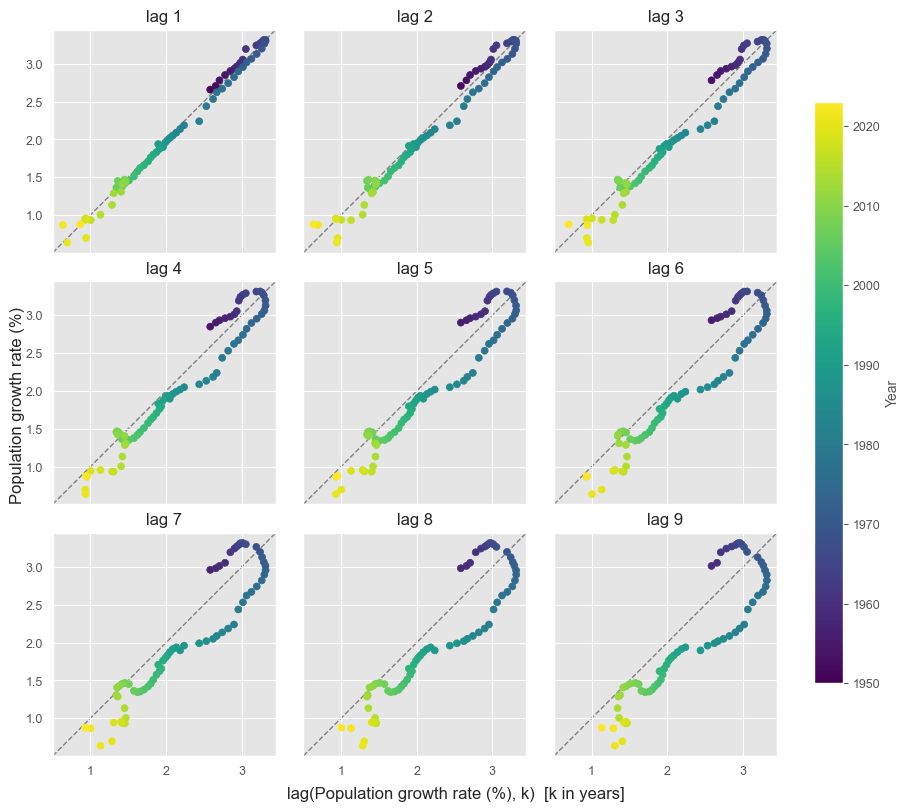

In [65]:
plot_lags(pop, "Population growth rate (%)")

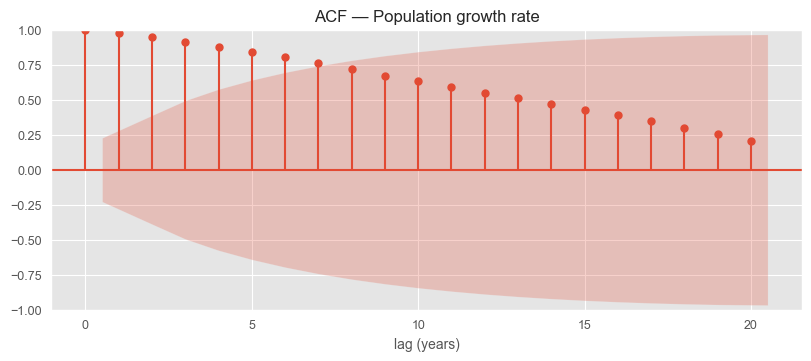

In [66]:
plot_autocorr(pop, "Population growth rate")

## 6. Life expectancy at birth (2000–2021)

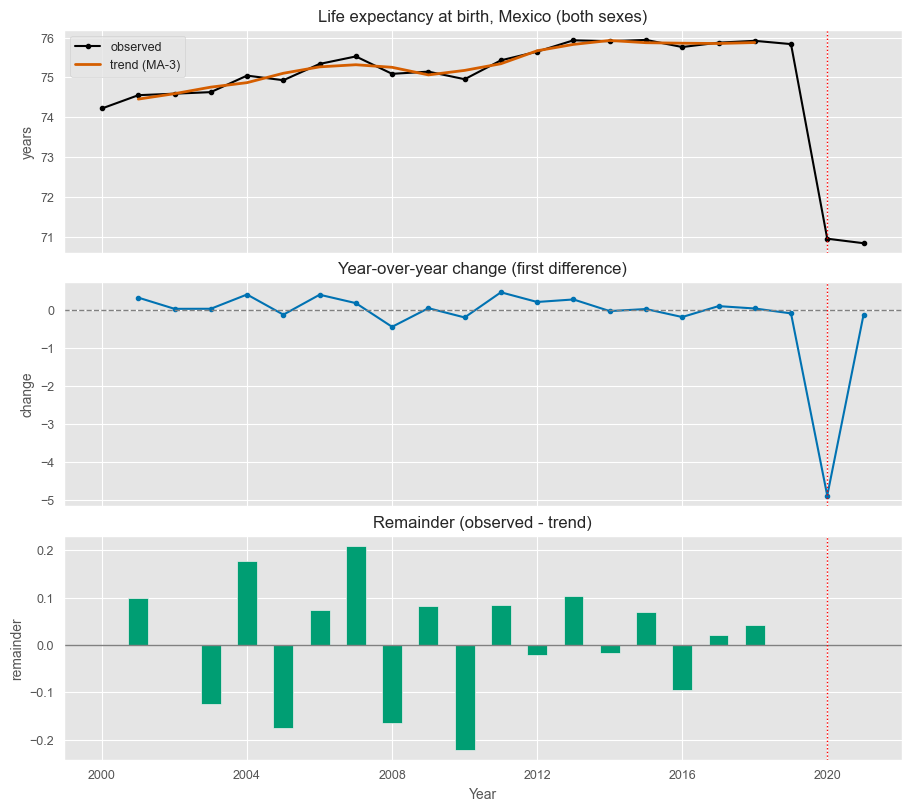

In [67]:
le_dec = plot_time_trend(le, "Life expectancy at birth, Mexico (both sexes)",
                         "years", window=3, mark_years=[2020], break_year=2020)

In [68]:
le_dec.reindex(le_dec["remainder"].abs().sort_values(ascending=False).index)[["year", "y", "trend", "remainder"]].head(5)

,year,y,trend,remainder
10,2010,74.953,75.174,-0.221
7,2007,75.525,75.316,0.208
4,2004,75.043,74.866,0.177
5,2005,74.927,75.102,-0.175
8,2008,75.087,75.251,-0.164


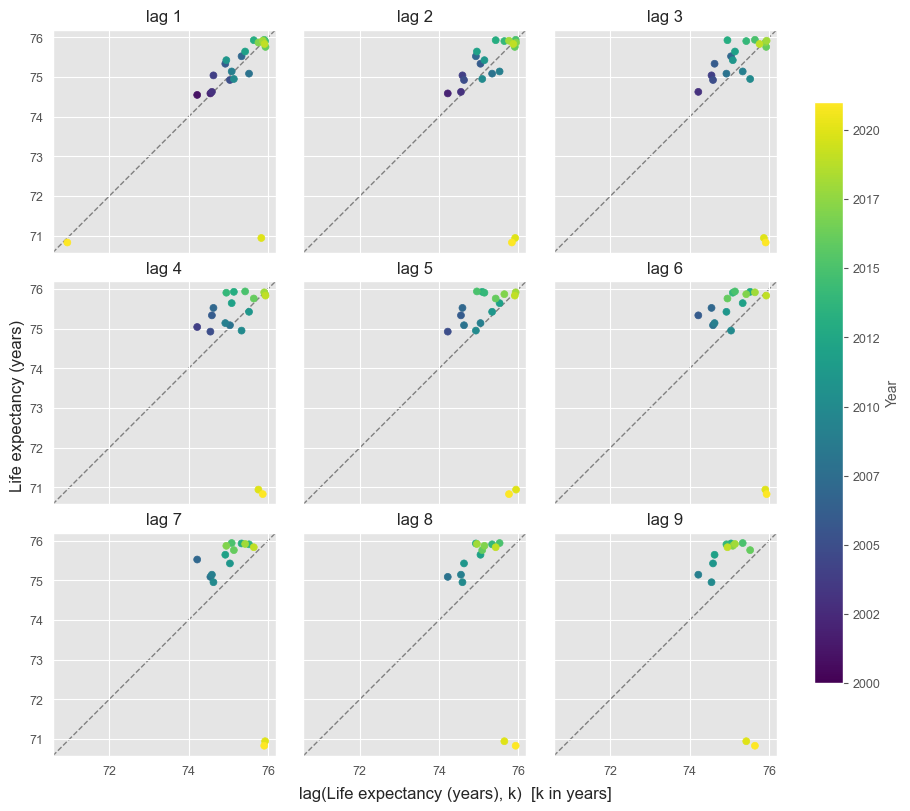

In [69]:
plot_lags(le, "Life expectancy (years)")

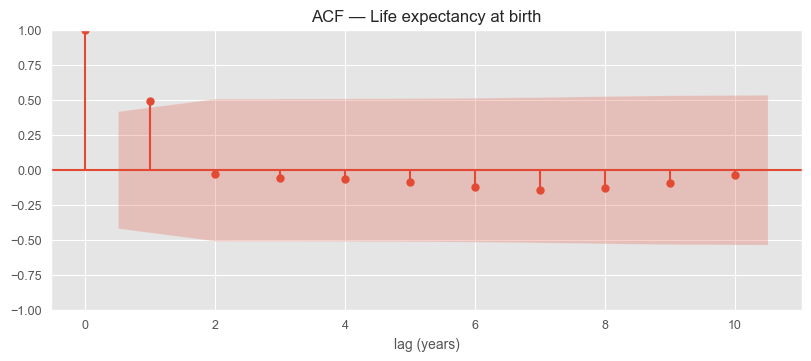

In [70]:
plot_autocorr(le, "Life expectancy at birth")

The 2020 drop is so large that it compresses the lag plots and distorts the ACF.
Repeating both on the **pre-pandemic period (2000–2019)** shows the underlying structure.

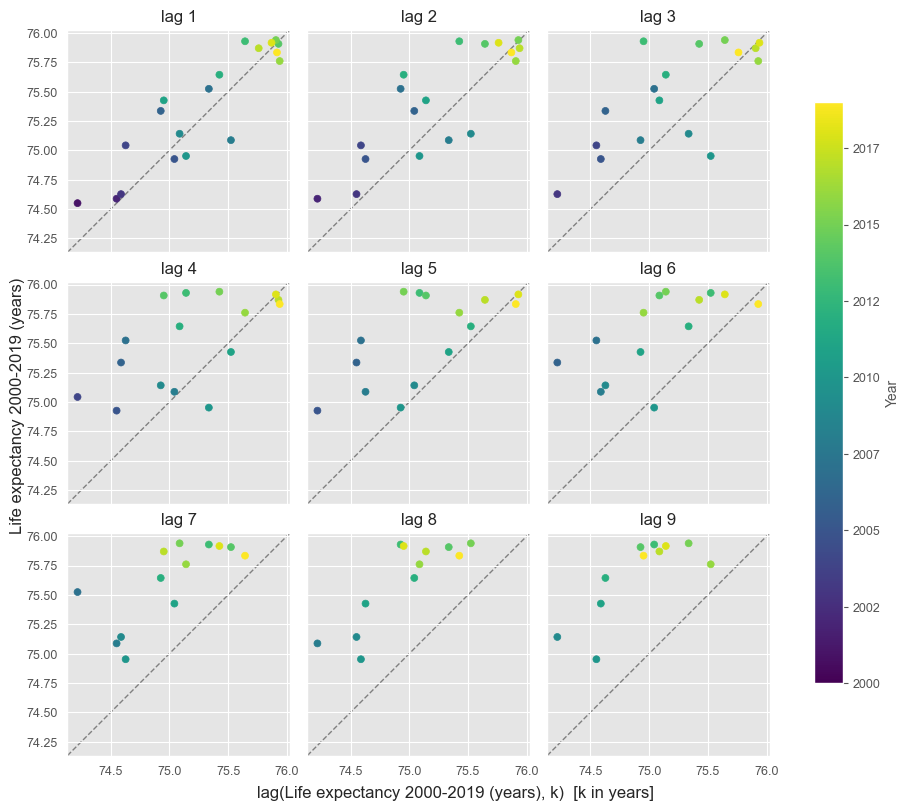

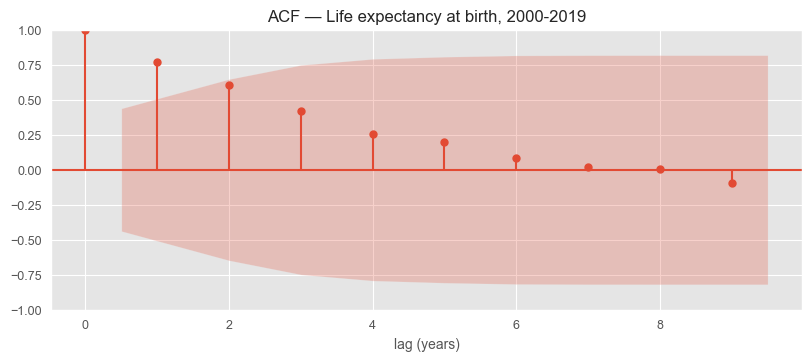

In [71]:
le_pre = le[le["year"] <= 2019]
plot_lags(le_pre, "Life expectancy 2000-2019 (years)")
plot_autocorr(le_pre, "Life expectancy at birth, 2000-2019")

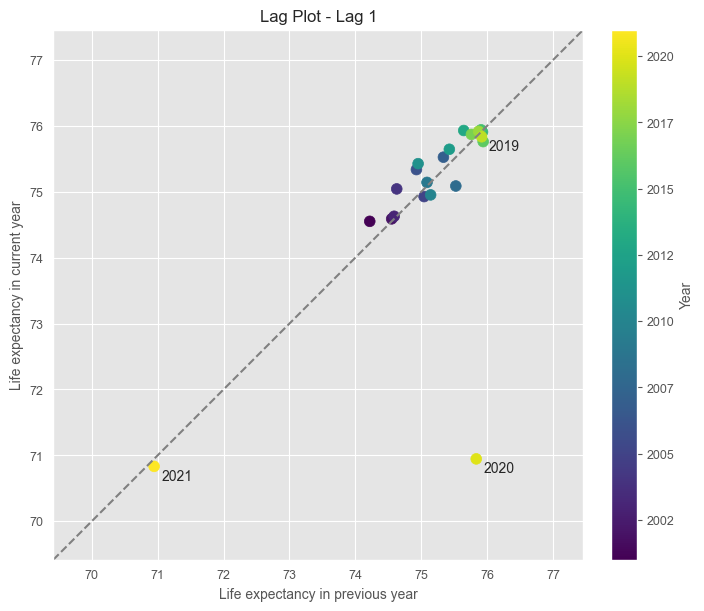

In [72]:
# Single lag-1 plot (same steps as in class: shift -> dropna -> scatter)
df = le.sort_values("ds").copy()
df["lag_1"] = df["y"].shift(1)
df = df.dropna(subset=["lag_1"])
lims = 0.98 * le["y"].min(), 1.02 * le["y"].max()

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(df["lag_1"], df["y"], c=df["year"], cmap="viridis", s=60)
for _, r in df[df["year"] >= 2019].iterrows():
    ax.annotate(int(r["year"]), (r["lag_1"], r["y"]), xytext=(5, -10), textcoords="offset points")
ax.plot(lims, lims, "--", color="gray")
ax.set(xlim=lims, ylim=lims, aspect="equal",
       xlabel="Life expectancy in previous year", ylabel="Life expectancy in current year",
       title="Lag Plot - Lag 1")
fig.colorbar(sc, ax=ax, label="Year", format="%d")
plt.show()

## 7. Top causes of death (2000–2023)

In [73]:
# Average rate per cause over the whole period (groupby + mean + sort, as in class)
mean_df = deaths.groupby("cause", as_index=False)["y"].mean()
mean_df.sort_values(by="y", ascending=False).head(10)

,cause,y
0,COVID-19,253.357
7,Ischaemic heart disease,85.662
4,Diabetes mellitus,56.212
2,Cirrhosis of the liver,37.087
6,Interpersonal violence,35.852
13,Stroke,28.103
8,Kidney diseases,27.830
1,Chronic obstructive pulmonary disease,23.220
11,Road injury,22.748
9,Lower respiratory infections,22.333


In [74]:
# How many years each cause appears in the top 10
deaths.groupby("cause")["year"].count().sort_values(ascending=False)

cause
Chronic obstructive pulmonary disease    24
Cirrhosis of the liver                   24
Diabetes mellitus                        24
Interpersonal violence                   24
Ischaemic heart disease                  24
Kidney diseases                          24
Lower respiratory infections             24
Road injury                              24
Stroke                                   24
Congenital anomalies                     14
Hypertensive heart disease                5
COVID-19                                  3
Prostate cancer                           1
Self-harm                                 1
Name: year, dtype: int64

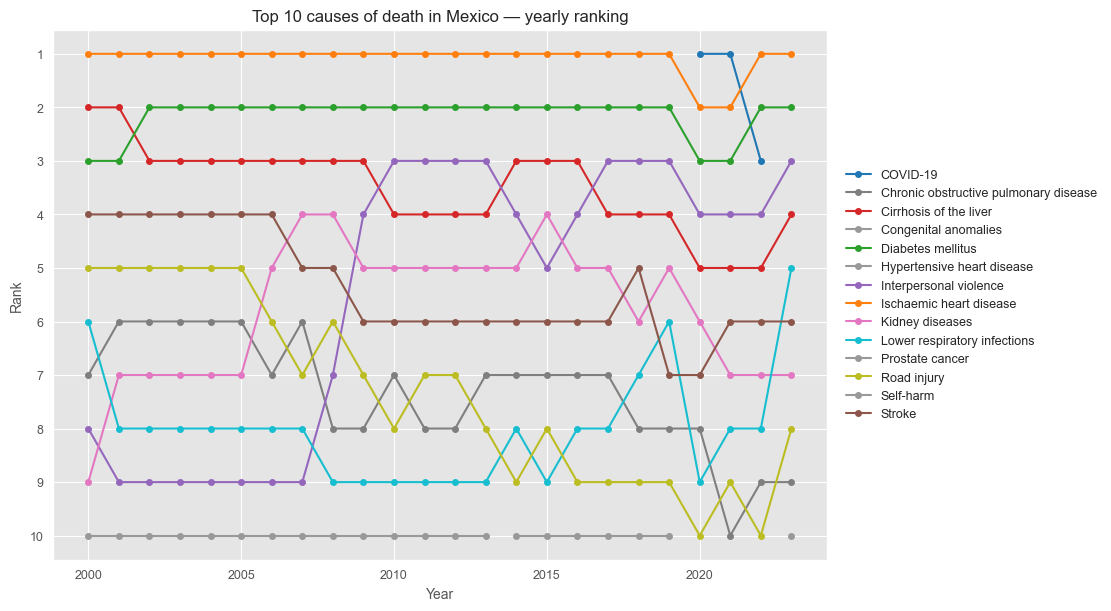

In [75]:
# Ranking over time (bump chart)
causes = deaths.groupby("cause")["y"].mean().sort_values(ascending=False).index
main = deaths.groupby("cause")["year"].count().loc[lambda c: c == deaths["year"].nunique()].index  # causes present every year
palette = dict(zip([c for c in causes if c in main or c == "COVID-19"], sns.color_palette("tab10", 10)))
palette.update({c: "0.6" for c in causes if c not in palette})

fig, ax = plt.subplots(figsize=(11, 6))
for cause, d in deaths.groupby("cause"):
    ax.plot(d["year"], d["rank"], marker="o", ms=4, color=palette[cause], label=cause)
ax.invert_yaxis()
ax.set_yticks(range(1, 11))
ax.set(title="Top 10 causes of death in Mexico — yearly ranking", xlabel="Year", ylabel="Rank")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

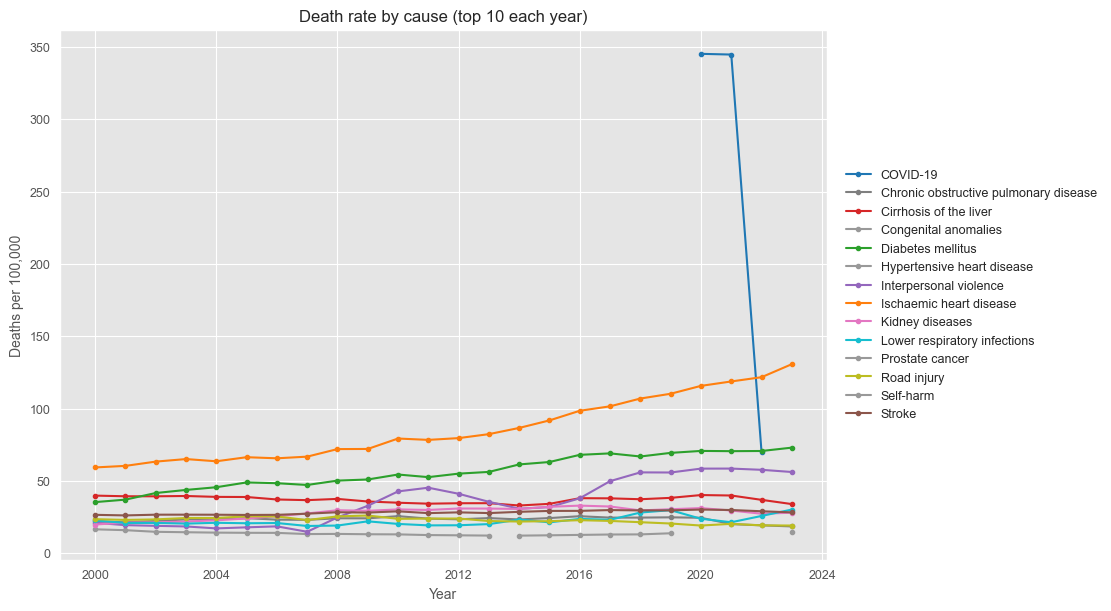

In [76]:
# Death rate over time for each cause
fig, ax = plt.subplots(figsize=(11, 6))
for cause, d in deaths.groupby("cause"):
    ax.plot(d["ds"], d["y"], marker="o", ms=3, color=palette[cause], label=cause)
ax.set(title="Death rate by cause (top 10 each year)", xlabel="Year", ylabel="Deaths per 100,000")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

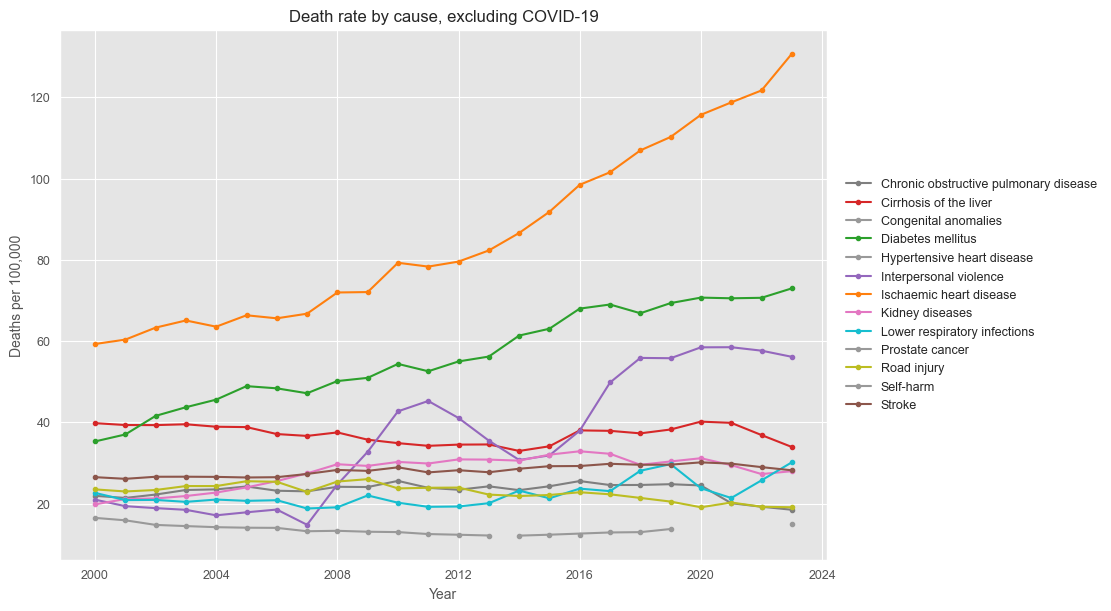

In [77]:
# Same chart without COVID-19, to see the chronic diseases more clearly
fig, ax = plt.subplots(figsize=(11, 6))
for cause, d in deaths[deaths["cause"] != "COVID-19"].groupby("cause"):
    ax.plot(d["ds"], d["y"], marker="o", ms=3, color=palette[cause], label=cause)
ax.set(title="Death rate by cause, excluding COVID-19", xlabel="Year", ylabel="Deaths per 100,000")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

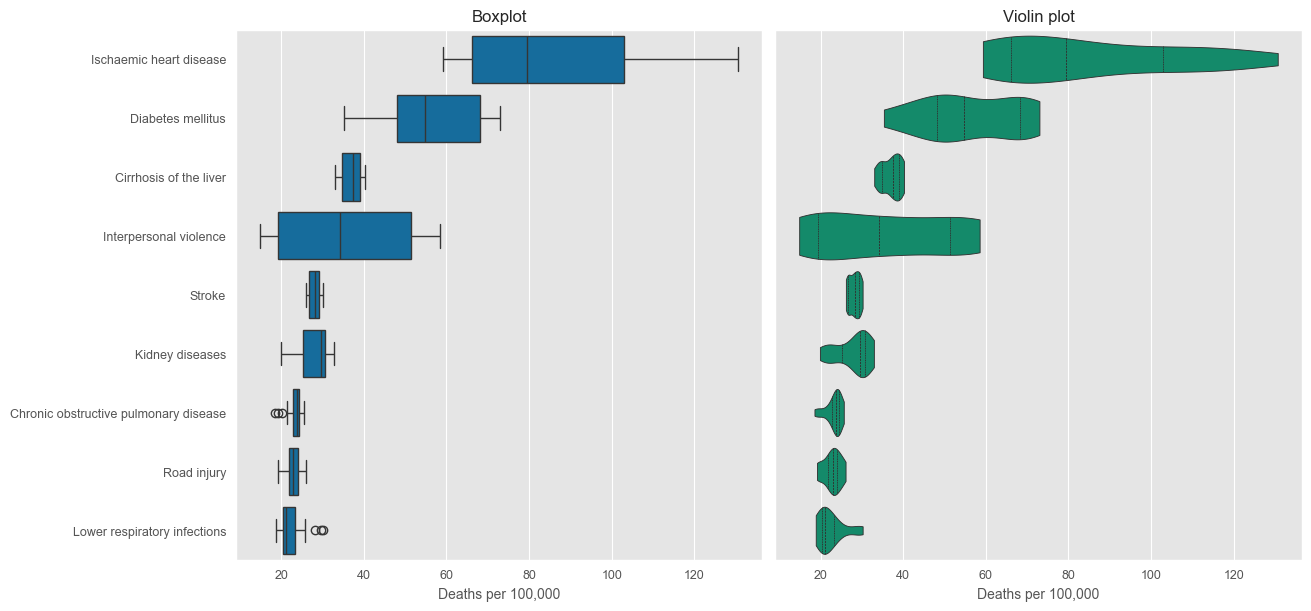

In [78]:
# Distribution of each cause over the years (boxplot and violin, as in class)
# Causes present in all 24 years
# only the causes that appear in all years (a box of 1-5 points is not informative)
order = [c for c in causes if c in main]
d = deaths[deaths["cause"].isin(order)]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
sns.boxplot(data=d, y="cause", x="y", order=order, ax=axes[0], color="#0072B2")
axes[0].set(title="Boxplot", xlabel="Deaths per 100,000", ylabel="")
sns.violinplot(data=d, y="cause", x="y", order=order, ax=axes[1], color="#009E73",
               cut=0, density_norm="width", inner="quart")
axes[1].set(title="Violin plot", xlabel="Deaths per 100,000", ylabel="")
plt.show()

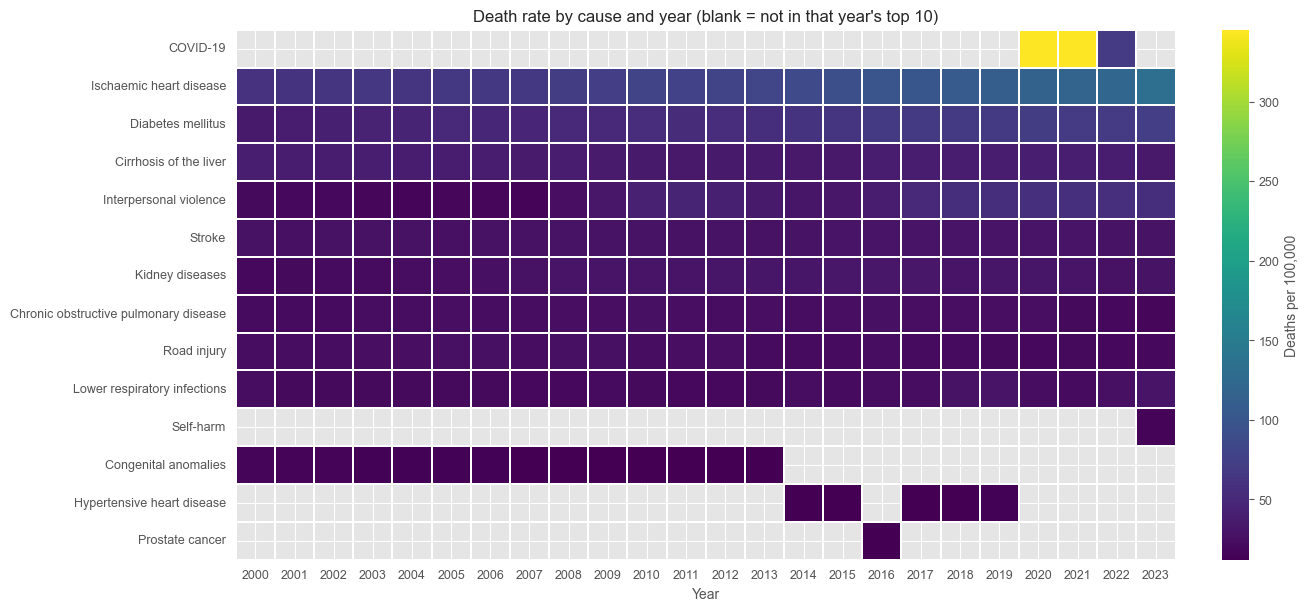

In [79]:
# Heatmap year x cause
heat = deaths.pivot(index="cause", columns="year", values="y").loc[causes]
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(heat, cmap="viridis", ax=ax, cbar_kws={"label": "Deaths per 100,000"}, linewidths=.3)
ax.set(title="Death rate by cause and year (blank = not in that year's top 10)", xlabel="Year", ylabel="")
plt.show()

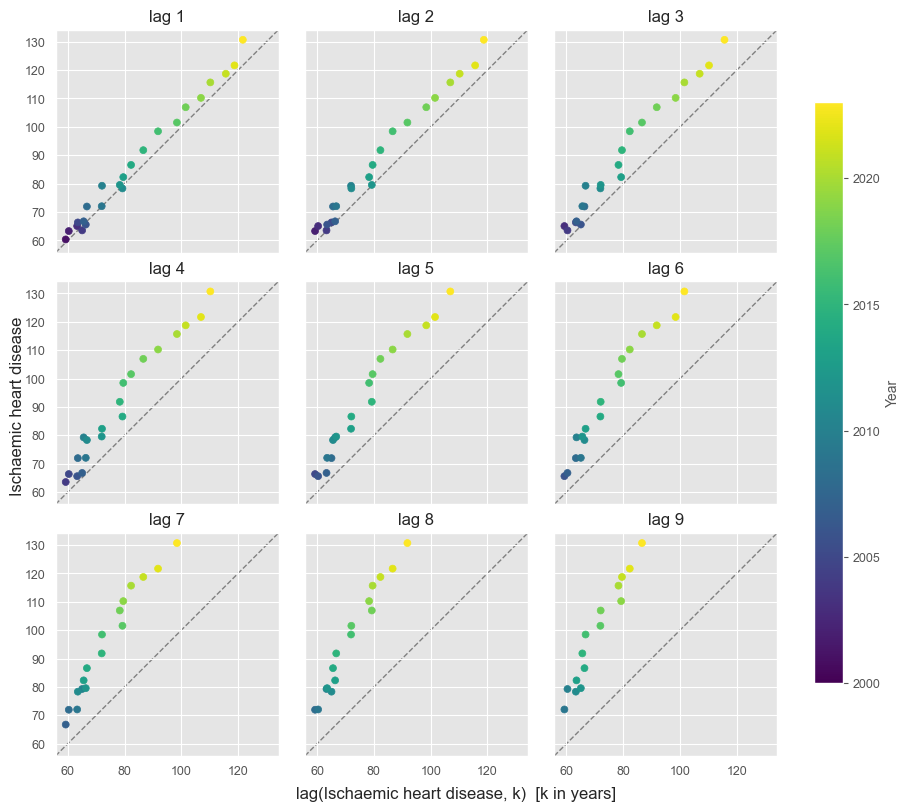

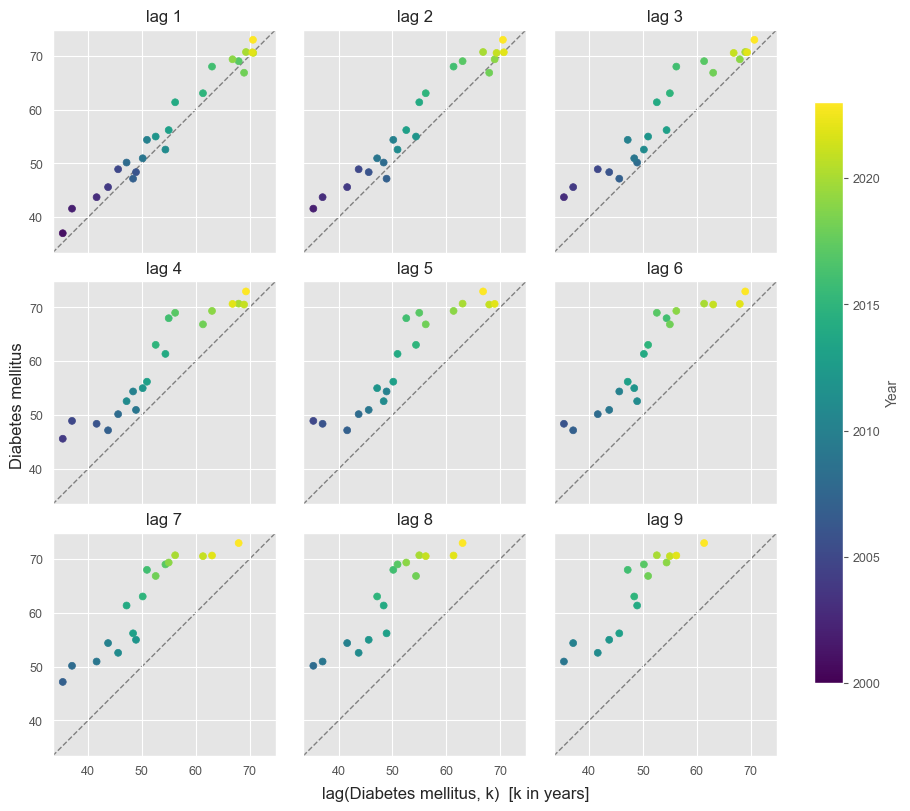

In [80]:
# Lag plots for the two leading chronic causes (present in all 24 years)
for cause in ["Ischaemic heart disease", "Diabetes mellitus"]:
    plot_lags(deaths[deaths["cause"] == cause], cause)

## 8. Risk factors
These cells continue the notebook: they reuse the setup cell and the helper functions
`summary`, `plot_time_trend`, `plot_lags` and `plot_autocorr` defined above.

| Risk factor | WHO indicator | Unit |
|---|---|---|
| Hypertension (age 30–79) | NCD_HYP_PREVALENCE_A | % of adults |
| Tobacco use (age 15+) | M_Est_tob_curr_std | % of population |
| Alcohol consumption (age 15+) | SA_0000001688 | litres of pure alcohol per capita |
| Adult obesity (age 18+) | NCD_BMI_30A | % of adults |
| Safely managed drinking water | WSH_WATER_SAFELY_MANAGED | % of population |

Only the **TOTAL** (both sexes) values are used.

In [81]:
# File names (edit here if your local file names differ)
rf_files = {
    "Hypertension":   ("Prevalencia de hipertencion en adultos entre 30 y 79.xlsx", "RATE_PER_100_N"),
    "Tobacco use":    ("Prevalencia de uso de tabaco en mayores de 15.xlsx", "PERCENT_POP_N"),
    "Alcohol":        ("Consumo de alcohol mayores de 15.xlsx", "RATE_PER_CAPITA_N"),
    "Adult obesity":  ("Obesidad en adultos mayores.xlsx", "RATE_PER_100_N"),
    "Drinking water": ("población que utiliza servicios de agua potable gestionados de forma segura.xlsx", "PERCENT_POP_N"),
}
rf_units = {
    "Hypertension": "% of adults 30-79",
    "Tobacco use": "% of population 15+",
    "Alcohol": "litres per capita 15+",
    "Adult obesity": "% of adults 18+",
    "Drinking water": "% of population",
}

frames = []
for name, (file, col) in rf_files.items():
    raw = pd.read_excel(file)
    if "DIM_SEX" in raw.columns:
        raw = raw[raw["DIM_SEX"] == "TOTAL"]
    tmp = raw[["DIM_TIME", col]].rename(columns={"DIM_TIME": "year", col: "y"})
    # lower / upper uncertainty bounds, when the file provides them
    tmp["y_low"] = raw[col + "L"].values if col + "L" in raw.columns else np.nan
    tmp["y_up"] = raw[col + "U"].values if col + "U" in raw.columns else np.nan
    tmp["unique_id"] = name
    frames.append(tmp)

rf = (pd.concat(frames, ignore_index=True)
      .sort_values(["unique_id", "year"])
      .reset_index(drop=True))
rf["ds"] = pd.to_datetime(rf["year"].astype(str))
rf.head(10)

,year,y,y_low,y_up,unique_id,ds
0,1990,14.507,12.957,16.217,Adult obesity,1990-01-01
1,1991,15.199,13.758,16.786,Adult obesity,1991-01-01
2,1992,15.901,14.536,17.377,Adult obesity,1992-01-01
3,1993,16.610,15.326,17.977,Adult obesity,1993-01-01
4,1994,17.321,16.089,18.636,Adult obesity,1994-01-01
5,1995,18.035,16.855,19.273,Adult obesity,1995-01-01
6,1996,18.751,17.614,19.936,Adult obesity,1996-01-01
7,1997,19.467,18.373,20.611,Adult obesity,1997-01-01
8,1998,20.178,19.126,21.277,Adult obesity,1998-01-01
9,1999,20.881,19.878,21.915,Adult obesity,1999-01-01


### 8.1 Coverage and data quality

In [82]:
rf_coverage = rf.groupby("unique_id").agg(
    first_year=("year", "min"),
    last_year=("year", "max"),
    n_obs=("year", "count"),
)
# A series is regular (annual) if it has one observation for every year in its range
rf_coverage["annual_without_gaps"] = (rf_coverage["last_year"] - rf_coverage["first_year"] + 1) == rf_coverage["n_obs"]
rf_coverage

,first_year,last_year,n_obs,annual_without_gaps
unique_id,,,,
Adult obesity,1990,2022,33,True
Alcohol,2000,2022,23,True
Drinking water,2000,2024,25,True
Hypertension,1990,2019,30,True
Tobacco use,2000,2030,11,False


In [83]:
# Years observed for the irregular series
rf.loc[rf["unique_id"] == "Tobacco use", "year"].tolist()

[2000, 2005, 2007, 2010, 2015, 2020, 2022, 2023, 2024, 2025, 2030]

In [84]:
# Repeated values in consecutive years (usually a value carried forward, not a real observation)
for name, g in rf.groupby("unique_id"):
    g = g.sort_values("year")
    rep = g.loc[g["y"].diff() == 0, "year"].tolist()
    if rep:
        print(f"{name}: value repeated from the previous year in {rep}")

Alcohol: value repeated from the previous year in [2001, 2022]
Hypertension: value repeated from the previous year in [2007, 2009]


In [85]:
# Tobacco use includes WHO projections for years after the last survey-based estimate
LAST_OBSERVED_TOBACCO = 2024
rf["projection"] = (rf["unique_id"] == "Tobacco use") & (rf["year"] > LAST_OBSERVED_TOBACCO)
rf.loc[rf["projection"], ["unique_id", "year", "y"]]

,unique_id,year,y
120,Tobacco use,2025,15.6
121,Tobacco use,2030,14.7


### 8.2 Summary statistics

In [86]:
rf.loc[~rf["projection"]].groupby("unique_id")["y"].apply(summary).unstack()

,n,mean,std,min,p25,median,p75,max
unique_id,,,,,,,,
Adult obesity,33.0,25.376,6.442,14.507,20.178,25.385,30.692,36.030
Alcohol,23.0,5.452,0.337,5.068,5.136,5.375,5.696,6.011
Drinking water,25.0,41.604,0.928,40.015,40.858,41.647,42.385,42.967
Hypertension,30.0,33.343,1.637,29.500,32.400,33.750,34.750,35.100
Tobacco use,9.0,17.911,1.976,15.700,16.100,17.600,19.400,21.200


### 8.3 Overview of all risk factors

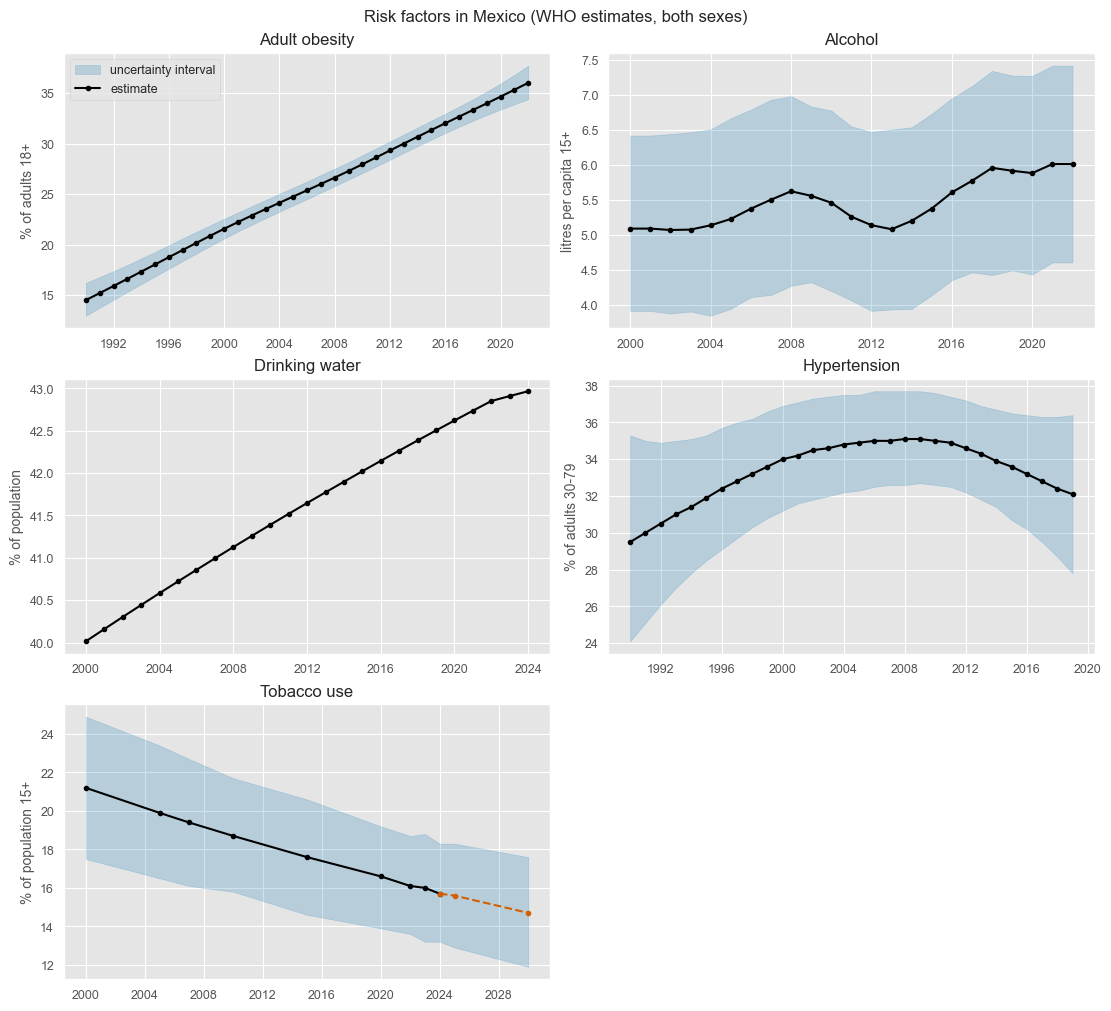

In [87]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, (name, g) in zip(axes.flat, rf.groupby("unique_id")):
    obs = g[~g["projection"]]
    ax.fill_between(g["ds"], g["y_low"], g["y_up"], color="#0072B2", alpha=0.2,
                    label="uncertainty interval")
    ax.plot(obs["ds"], obs["y"], marker="o", ms=3, color="#000000", label="estimate")
    proj = g[g["year"] >= LAST_OBSERVED_TOBACCO] if g["projection"].any() else None
    if proj is not None:
        ax.plot(proj["ds"], proj["y"], ls="--", marker="o", ms=3, color="#D55E00", label="WHO projection")
    ax.set(title=name, ylabel=rf_units[name])
axes.flat[0].legend(loc="best")
axes.flat[-1].axis("off")
fig.suptitle("Risk factors in Mexico (WHO estimates, both sexes)")
plt.show()

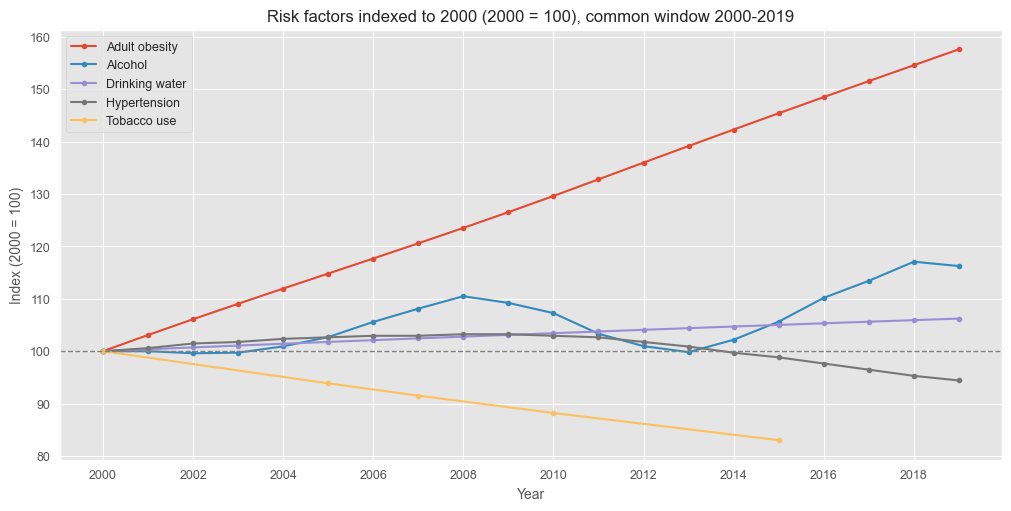

In [88]:
# Common window to compare directions of change: index each series to its 2000 value (2000 = 100)
rf_window = rf[(rf["year"] >= 2000) & (rf["year"] <= 2019) & (~rf["projection"])].copy()
rf_window["index_2000"] = rf_window.groupby("unique_id")["y"].transform(lambda s: 100 * s / s.iloc[0])

fig, ax = plt.subplots(figsize=(10, 5))
for name, g in rf_window.groupby("unique_id"):
    ax.plot(g["ds"], g["index_2000"], marker="o", ms=3, label=name)
ax.axhline(100, color=".5", ls="--", lw=1)
ax.set(title="Risk factors indexed to 2000 (2000 = 100), common window 2000-2019",
       xlabel="Year", ylabel="Index (2000 = 100)")
ax.legend(loc="upper left")
plt.show()

In [89]:
# Percentage change over the common window (tobacco: last observation inside the window is 2015)
(rf_window.groupby("unique_id")
 .agg(first_year=("year", "first"), first_value=("y", "first"),
      last_year=("year", "last"), last_value=("y", "last"))
 .assign(pct_change=lambda d: 100 * (d["last_value"] / d["first_value"] - 1)))

,first_year,first_value,last_year,last_value,pct_change
unique_id,,,,,
Adult obesity,2000,21.570,2019,33.996,57.611
Alcohol,2000,5.088,2019,5.915,16.245
Drinking water,2000,40.015,2019,42.504,6.221
Hypertension,2000,34.000,2019,32.100,-5.588
Tobacco use,2000,21.200,2015,17.600,-16.981


### 8.4 Trend, change and remainder per risk factor
Same decomposition as for the other series (annual data: trend + remainder, no seasonal component).
Tobacco use is excluded here because its observations are not equally spaced.

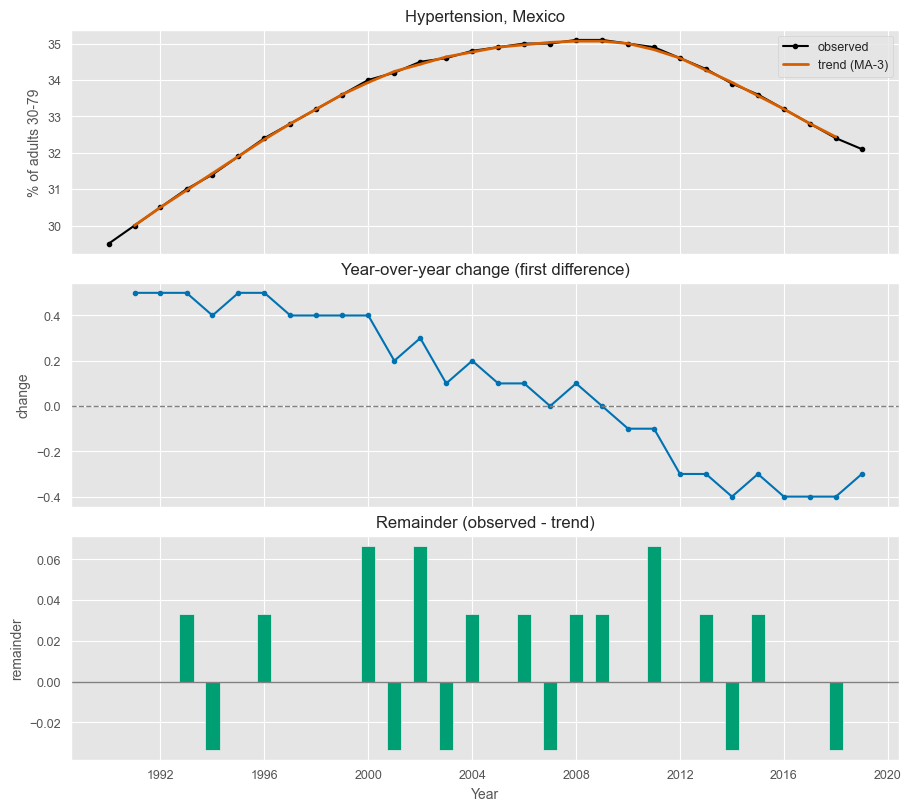

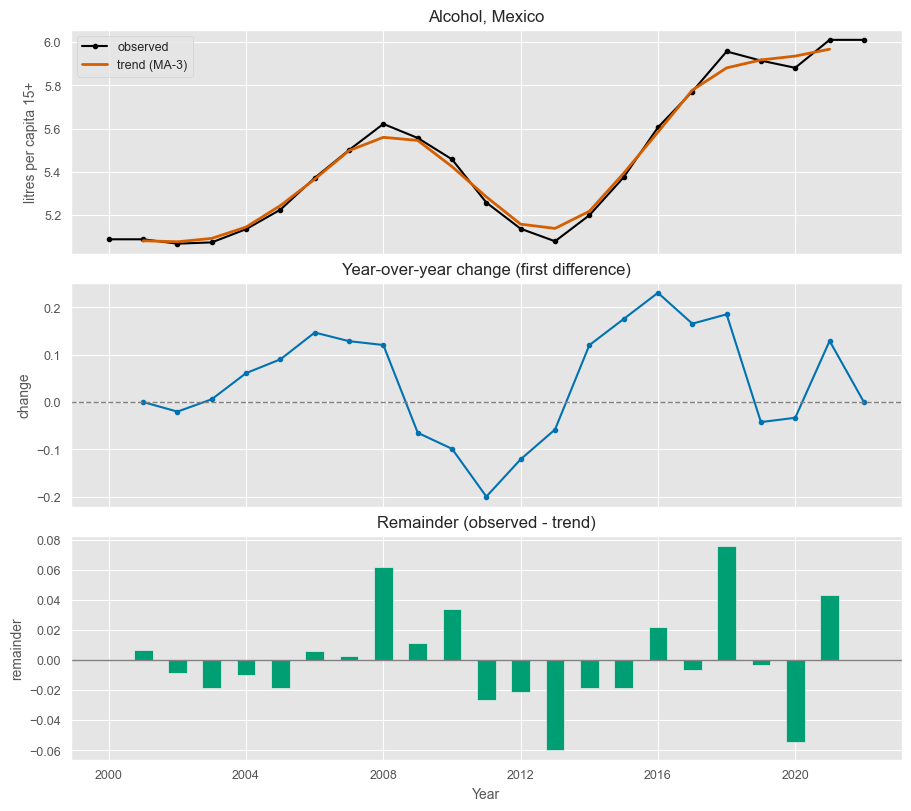

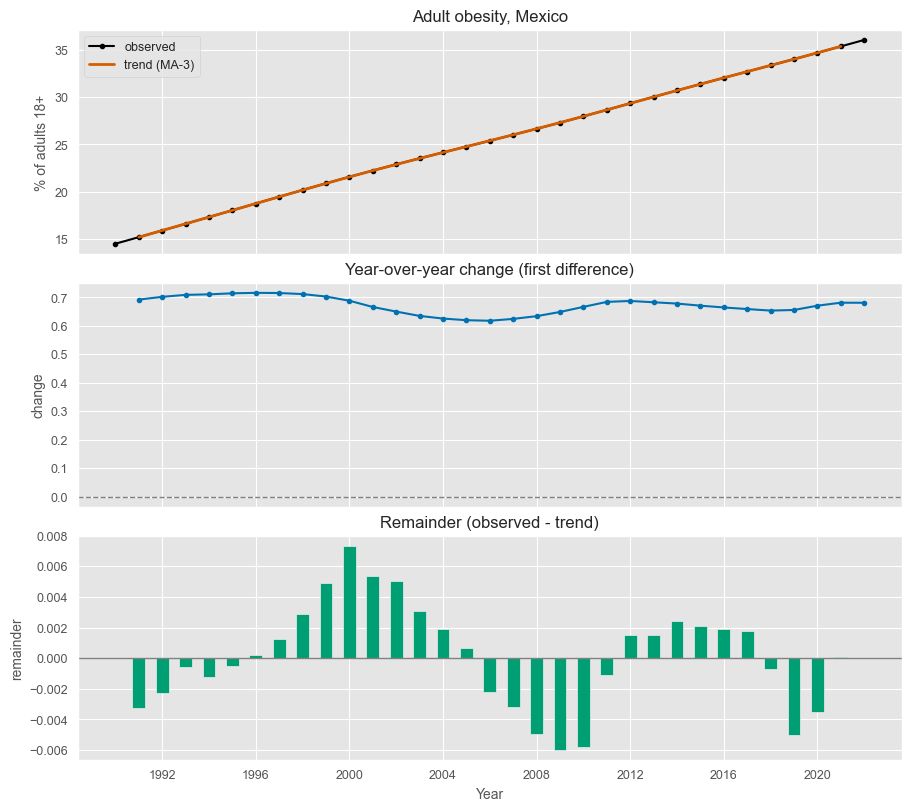

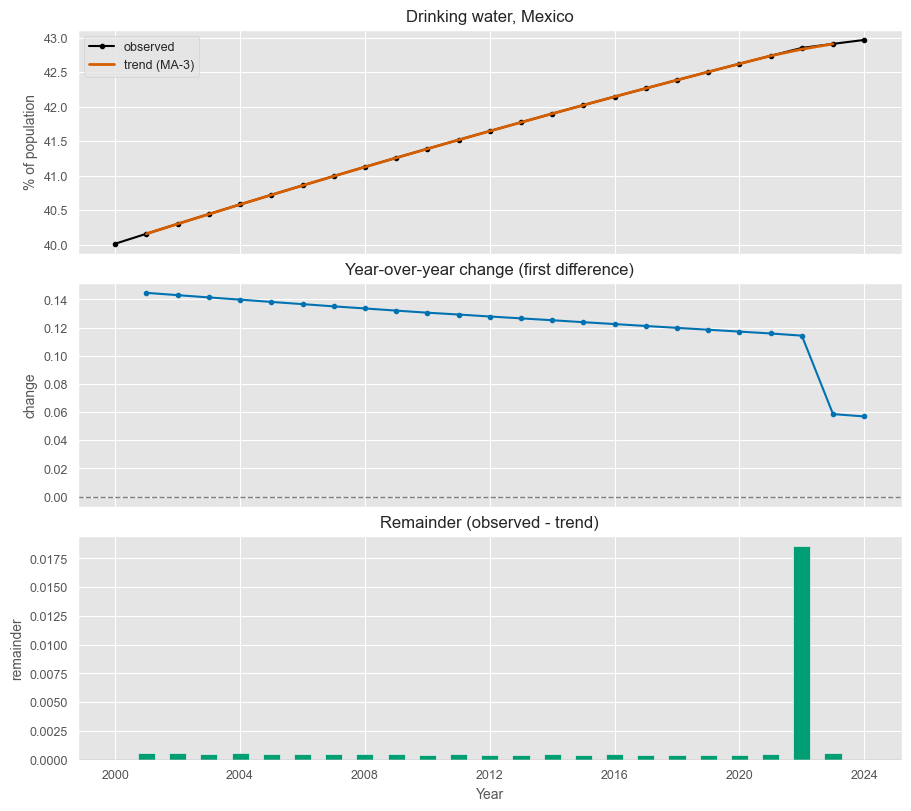

In [90]:
rf_annual = ["Hypertension", "Alcohol", "Adult obesity", "Drinking water"]
for name in rf_annual:
    g = rf[rf["unique_id"] == name]
    plot_time_trend(g, f"{name}, Mexico", rf_units[name], window=3)

### 8.5 Lag plots and ACF (annual series only)

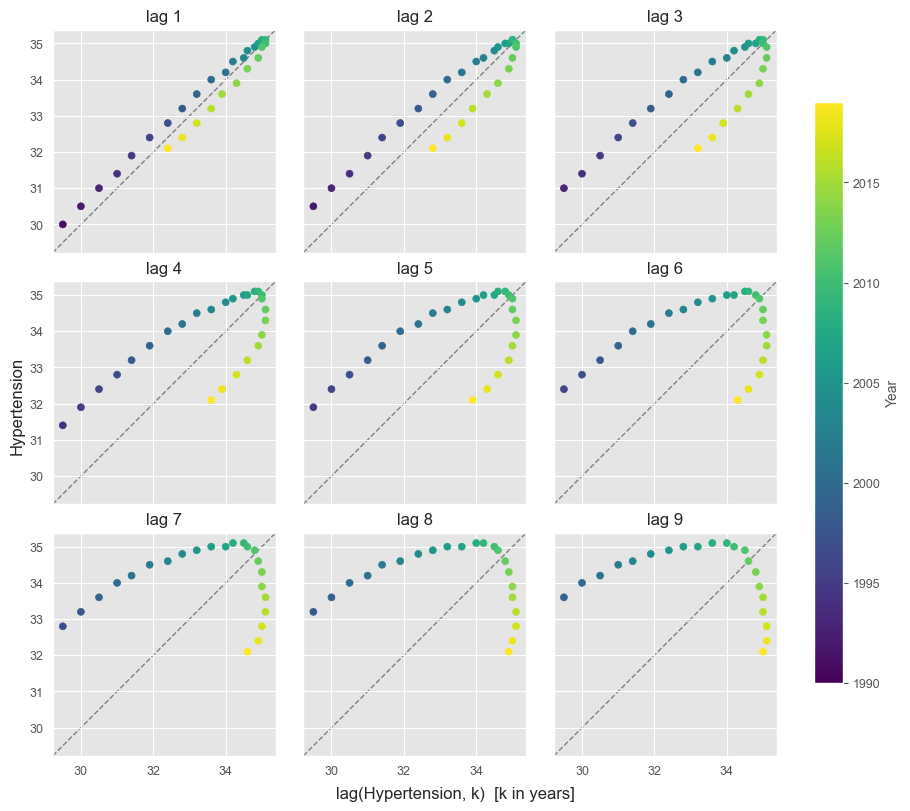

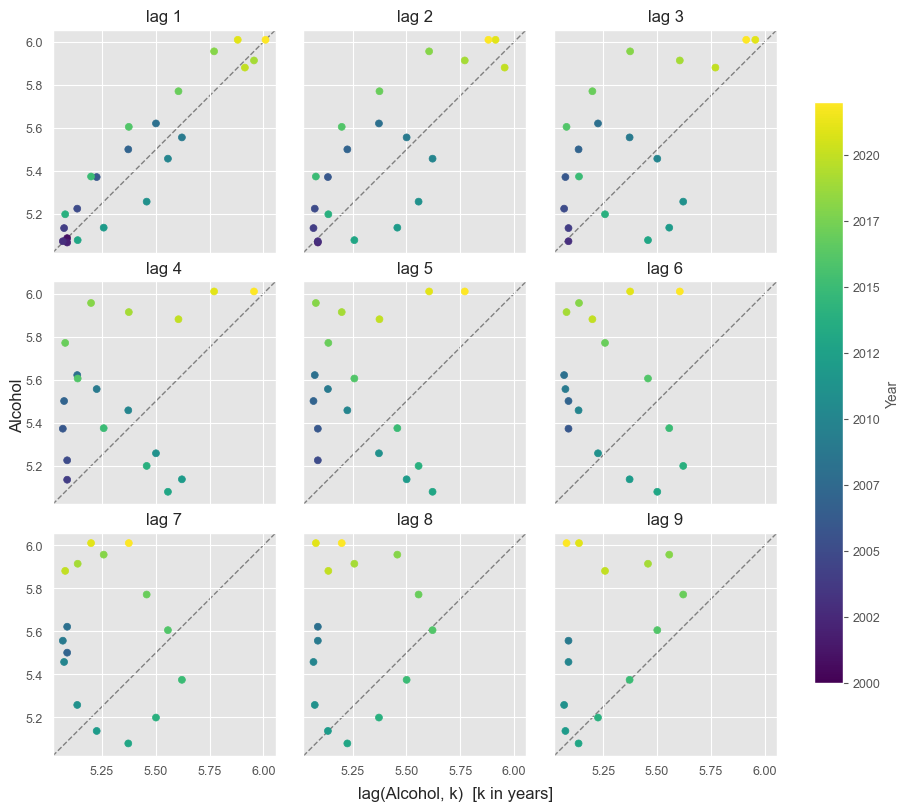

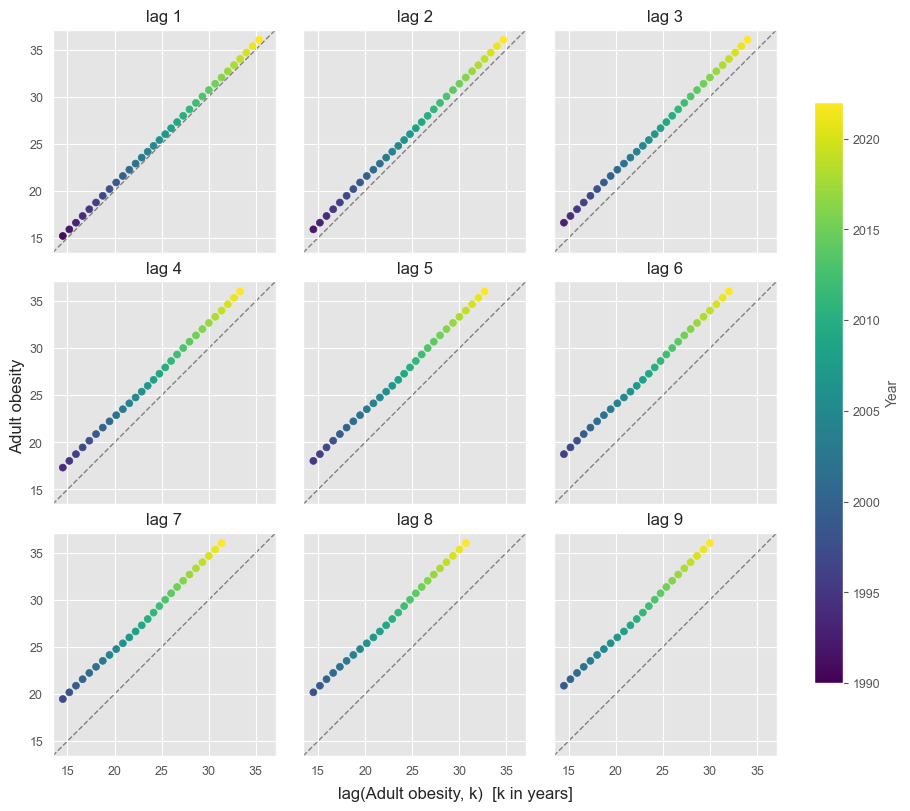

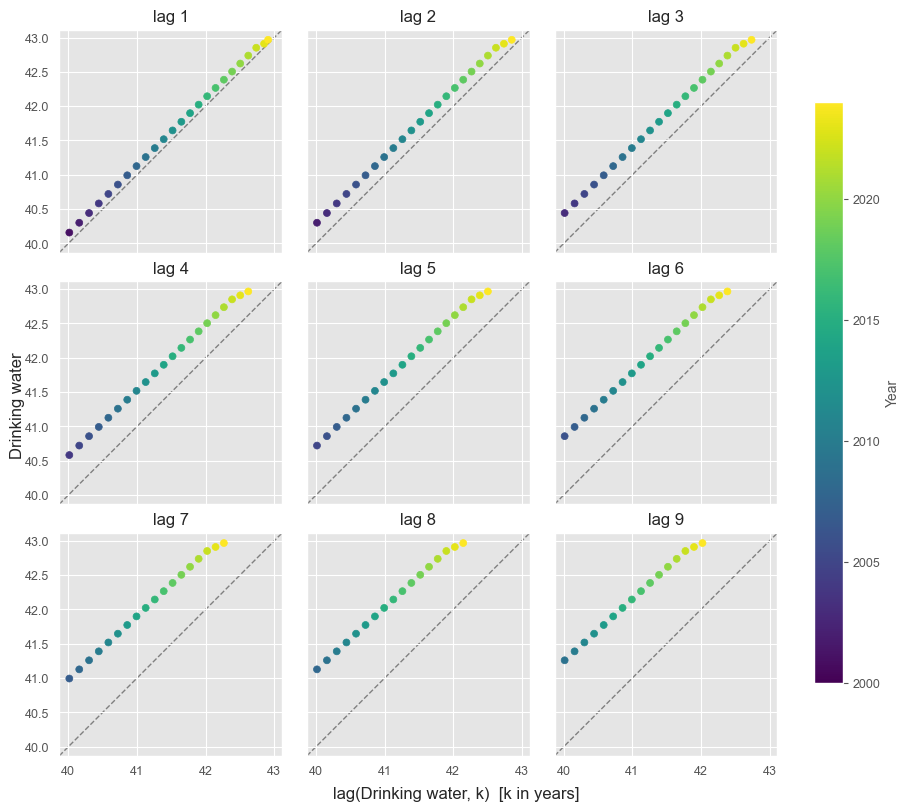

In [91]:
for name in rf_annual:
    plot_lags(rf[rf["unique_id"] == name], name)

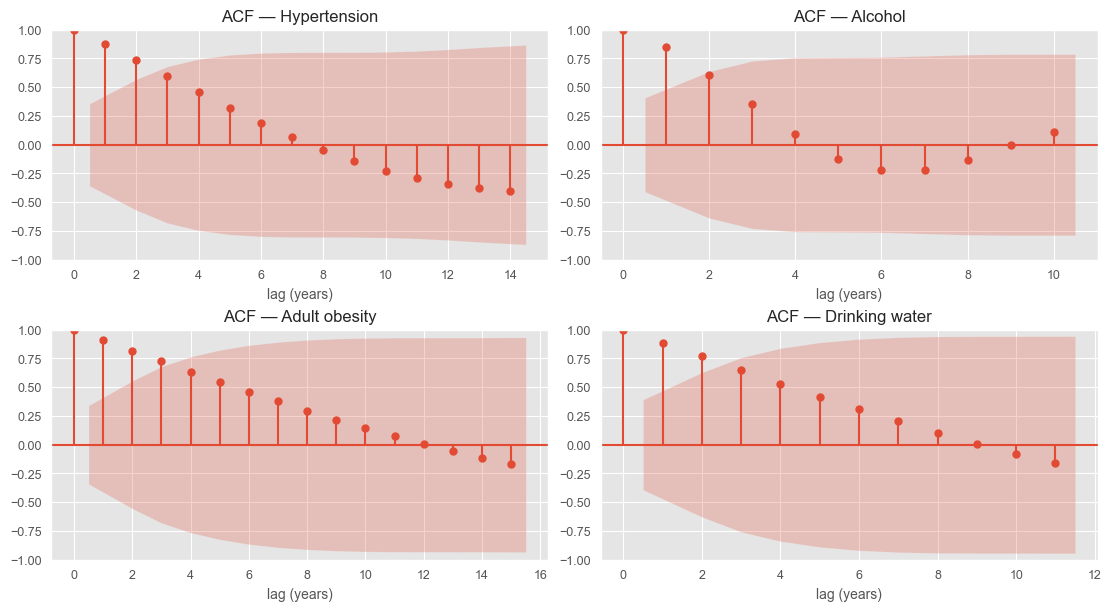

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, name in zip(axes.flat, rf_annual):
    s = rf.loc[rf["unique_id"] == name, "y"]
    plot_acf(s, lags=min(15, len(s) // 2 - 1), ax=ax)
    ax.set(title=f"ACF — {name}", xlabel="lag (years)")
plt.show()

### 8.6 Tobacco use (irregular observations)

In [93]:
g = rf[rf["unique_id"] == "Tobacco use"].copy()
g["years_since_previous"] = g["year"].diff()
g["avg_change_per_year"] = g["y"].diff() / g["years_since_previous"]
g[["year", "y", "y_low", "y_up", "projection", "years_since_previous", "avg_change_per_year"]]

,year,y,y_low,y_up,projection,years_since_previous,avg_change_per_year
111,2000,21.2,17.5,24.9,False,NaN,NaN
112,2005,19.9,16.5,23.4,False,5.0,-0.260
113,2007,19.4,16.1,22.7,False,2.0,-0.250
114,2010,18.7,15.8,21.7,False,3.0,-0.233
115,2015,17.6,14.6,20.6,False,5.0,-0.220
116,2020,16.6,13.9,19.2,False,5.0,-0.200
117,2022,16.1,13.6,18.7,False,2.0,-0.250
118,2023,16.0,13.2,18.8,False,1.0,-0.100
119,2024,15.7,13.2,18.3,False,1.0,-0.300
120,2025,15.6,12.9,18.3,True,1.0,-0.100
